# ETF Creation/Redemption Arbitrage: An Analytical Case Study (IWV)
This is an **analytical project only**. There is no live or paper trading.
The first run downloads all data into `data/` (about 6 minutes, mostly stock
prices). Later runs read from there, so the numbers stay the same as in the text.


## Hypothesis

An ETF has a fair value: the total market value of the stocks it holds, divided by the
number of ETF shares. This is simple arithmetic, not an assumption about how efficient
the market is. The ETF's trading price can drift away from this fair value for a while.

An Authorized Participant (AP, a large institution allowed to create and redeem ETF
shares) can profit from that gap with near certainty. They can swap ETF shares for the
underlying stocks (or the other way around) at fair value, instead of waiting for the
market price to correct itself.

This project rebuilds that mechanism for a real group of ETFs. It then compares two ways
of protecting the position while the swap settles: hedging with the exact stocks, or
hedging with other ETFs.

## The mechanism

- Fair value per share = (market value of all stocks in the basket) / (ETF shares
  outstanding).
- An AP can swap ETF shares for the basket of stocks, or the basket for new ETF shares,
  **at fair value**. This skips the ETF's own bid and ask prices entirely.
- **Premium case** (ETF price above fair value): buy the stocks, hand them to the
  issuer in exchange for new ETF shares ("create"), and sell those shares at the high
  market price. The selling pushes the ETF price down.
- **Discount case** (ETF price below fair value): buy the cheap ETF, hand it to the
  issuer in exchange for the stocks ("redeem"), and sell the stocks at their higher
  market value. The buying pushes the ETF price up.
- In both cases the trade itself pushes the price back toward fair value.

## Why a hedge is needed

The swap is not instant. For standard U.S. equity ETFs it settles on the normal stock
cycle: **T+1**, meaning the trade date (T) plus one business day. This has been the rule
since May 2024 (it was T+2 before). ETFs holding international or less liquid assets can
take longer.

There are two different clocks here:

- **Price correction is fast.** Seconds to minutes. Other market participants act on the
  expected arbitrage and move quotes right away.
- **Settlement of your own swap is slow.** T+1 or more, no matter how fast the market
  corrects.

During that wait, someone who only bought the cheap ETF simply owns an ETF. If the market
falls, they lose money, even though they never wanted a bet on the market.

There is a second reason. The calculation tells us that the ETF and its basket are priced
differently. It does not tell us which of the two is wrong: the ETF could be too cheap, the
stocks could be too expensive, or both. Buying only the ETF is a bet that the ETF is the
mispriced side, which is a position, not an arbitrage. Holding both sides earns the
difference between them, whichever side moves.

## How the hedge works, case by case

Take the discount case with simple numbers. The ETF trades at **99**. The basket of
stocks it holds is worth **100**. The gap is **1**. (Trading costs are ignored here and
added later.)

**Setup.** Buy the ETF at 99. At the same time, short the basket at 100 (sell the stocks
without owning them, and receive 100). Now both legs move together, so a general market
rise or fall cancels out. What you hold is the gap of 1.

**Case 1: the gap closes before settlement.** The ETF rises to 100, or the basket falls
to 99, or a bit of both. Sell the ETF, buy back the stocks. Profit: **1**.

**Case 2: the gap stays until settlement.** Redeem: hand in the ETF (cost 99) and receive
the stocks. Use those stocks to close the short (which brought in 100). Profit: **1**.

**Case 3: the gap gets worse.** The ETF falls to 98 while the basket stays at 100. On
paper you are down 1 for now, because the ETF you hold is worth less. But redeem anyway:
the ETF cost 99, and the stocks you receive close the short that brought in 100. Profit
is still **1**. The wider gap does not make this position earn more. It does make a
*new* position more attractive, since entering now would lock in 2 instead of 1. The only
cost is the temporary paper loss, which matters only if you are forced to close early
(for example by a margin call on the short).

**Why Cases 2 and 3 give the same profit.** The short is closed by handing over the
stocks received from the redemption, not by buying stocks in the market. So the final
profit depends only on the two entry prices (99 and 100) and not on any price that comes
later.

The **premium case** is the mirror image: short the expensive ETF, buy the basket, create
new ETF shares, and use them to close the short.

## What can actually go wrong

The gap getting worse is not on this list, because Case 3 shows it does not hurt a
position held to redemption. These are the risks that do matter:

1. **Wrong basket data.** If the holdings list is out of date (a rebalance, a corporate
   action), the stocks you receive do not match the stocks you shorted, and the hedge
   leaks.
2. **Trading costs at entry.** The profit of 1 assumes both legs trade at clean prices at
   the same moment. In reality, bid-ask spreads and price impact eat into the gap, and
   the effect grows with the number of stocks traded.
3. **Carrying costs.** Fees to borrow stocks for the short, plus dividends owed on the
   short, during the wait.
4. **Operational limits.** Minimum swap size (the creation unit), order cutoff times, and
   orders being rejected.

## The core comparison: two hedge designs

The hedge above uses the exact stocks. That is one choice, not the only one. This project
builds and compares both.

### A. Exact stock hedge (theoretical baseline)

Hedge with the exact stocks, in the exact quantities, that the swap will deliver.

- **Pro:** no basis risk. The stocks delivered by the swap close the hedge directly, so
  no market trade is needed to close it and the later prices never matter (Cases 2 and
  3 above).
- **Con:** costs and effort grow with the number of stocks. A broad ETF can hold
  hundreds of names, each with its own spread, liquidity, and borrow cost.

### B. ETF hedge (practical alternative)

Hedge with a few liquid ETFs that together cover the same stocks, sized using the index
ratio. For example, short a large and mid cap ETF plus a small cap ETF against a total
market ETF.

- **Pro:** simple. Two or three liquid instruments instead of hundreds of stocks. The
  hedge can also stay open and be reused for the next round of the same trade, instead
  of rebuilding a full stock short each time. Real APs use substitute baskets for
  exactly this reason.
- **Con:** the redemption delivers stocks, but the hedge is short ETFs, which is a
  different instrument. Closing takes two separate market trades (sell the stocks, buy
  back the ETFs), each at the price of that moment. The profit now depends on whether the
  basket and the hedge ETFs moved together while waiting. That risk is called **basis
  risk**: the hedge and the position do not move perfectly together. 

**Why build both.** Design A shows the mechanism works correctly (basis risk
should be close to zero by construction). Design B is the practical version. Measuring
how much basis risk that convenience costs, on real data, is a stronger result than
either design alone.

## What this notebook covers

Detection first, because everything else depends on it: **how big are the gaps between
IWV's price and its fair value, and how do they compare with what it costs to trade
them?** Then the own-estimate signal, Design A (the exact stock hedge), Design B (the
ETF hedge), and what the numbers say about the strategy.

## Fair value and data

The real strategy runs during the day. Whenever the ETF's price moves away from the value
of its basket, the trade can be done right then, at any point in the trading day. Testing
that would need prices at second intervals for the ETF and all 2,600 stocks, which free
data does not have.

What free data does have is one clean comparison per day: the ETF's **closing price**
against the fund's **official NAV** (net asset value: the fair value per share, calculated
from the 4pm closing prices and published by iShares). An AP who submits an order before
the cutoff is priced at that day's NAV, so "buy at the close, redeem at that day's NAV" is
a trade we can model with this data. The close is therefore used as a model of the
strategy. It is not the trading edge itself. It shows how large the gaps are, what costs
do to them, and where the limitations are.

The close is looked at in two ways:

- **Theoretical edge.** The gap to the official NAV, as if the NAV were known at the moment
  of the trade. This is an upper bound, because the official NAV is only published after
  the close.
- **Practical edge.** The gap to our own NAV estimate, built from the published holdings
  (shares of each stock times its price). This is the actual strategy: in real time the
  NAV always has to be estimated. It needs live data, so it is logged forward, one day per
  run, instead of backtested.

The daily gap per share is NAV minus the closing price, as a percentage of the closing
price. A positive gap is a discount (redeem), a negative gap is a premium (create).

## Costs an AP faces

An AP is not free of costs. The main ones:

1. **Trading costs on both legs.** Bid-ask spread and price impact on the ETF and on the
   stocks or hedge ETFs.
2. **Creation/redemption fee.** The issuer charges a flat fee on each order, set in the
   fund's prospectus. It is not counted in this notebook.
3. **Borrow and financing.** A fee to borrow stocks for the short, plus the cost of cash
   tied up during the wait.
4. **Dividends owed on the short** if an ex-dividend date falls inside the wait.
5. **Small exchange and regulatory fees** on sales.
6. **Operational costs.** Failed settlements, orders sent too late.

Real APs are usually large market makers with lower costs than an outsider, so a cost
model built on outsider costs is conservative. This project does not claim to know the
true AP cost. It reports the **breakeven cost** instead: how large costs would have to be
to wipe out the profit.

## Data

Three inputs, all free:

- **Official NAV per share and ETF shares outstanding**, daily since May 2000, from the
  iShares fund download.
- **IWV daily closing price** from Yahoo Finance, not adjusted for dividends so that it
  is comparable with NAV.
- **The latest holdings file** (exact shares of each stock), from the same iShares
  download. iShares only offers the latest snapshot, not a history. So the own-estimate
  signal (see the signal test below) cannot be backtested. It is logged forward instead,
  one row per run, so the notebook should be run after the close.

All downloads are stored in `data/` on the first run. That folder is not in the repository,
because the iShares and Yahoo data is for personal use only. Set `REFRESH = True` to
download everything again. `iwv_estimates.csv` is the forward log of own estimates. It is
the only file that cannot be downloaded again, so it is kept in the repository.

In [1]:
import html
import logging
import os
import re
import time
from datetime import datetime
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import yfinance as yf
from IPython.display import display

logging.getLogger("yfinance").setLevel(logging.CRITICAL)

REFRESH = False  # True: download everything again instead of reading data/
TICKER = "IWV"
DATA, ESTIMATES = "data", "iwv_estimates.csv"
FUND_URL = (
    "https://www.blackrock.com/varnish-api/blk-one01-product-data/product-data/api/v1/get-fund-document"
    "?appType=PRODUCT_PAGE&appSubType=ISHARES&targetSite=us-ishares&locale=en_US"
    "&portfolioId={}&component=fundDownload&userType=individual"
)
FUND_ID = {"IWV": 239714, "IWB": 239707, "IWM": 239710}
os.makedirs(DATA, exist_ok=True)

In [2]:
def fund_download(ticker):
    """The iShares fund workbook (holdings and NAV history) as text."""
    path = f"{DATA}/fund_{ticker}.xml"
    if REFRESH or not os.path.exists(path):
        response = requests.get(FUND_URL.format(FUND_ID[ticker]), headers={"User-Agent": "Mozilla/5.0"}, timeout=120)
        with open(path, "w") as f:
            f.write(response.text)
    with open(path) as f:
        return f.read()


def etf_closes():
    """Daily closing prices of IWV, IWB and IWM, not adjusted for dividends."""
    path = f"{DATA}/etf_closes.csv"
    if REFRESH or not os.path.exists(path):
        prices = yf.download(list(FUND_ID), start="2000-01-01", auto_adjust=False, progress=False)["Close"]
        prices.index = pd.to_datetime(prices.index).tz_localize(None)
        prices.to_csv(path)
    return pd.read_csv(path, index_col=0, parse_dates=True)


def read_sheet(xml, name):
    """One worksheet of the iShares SpreadsheetML download, as a list of rows."""
    part = next(p for p in xml.split("<ss:Worksheet ")[1:] if p.startswith(f'ss:Name="{name}"'))
    rows = re.findall(r"<ss:Row[ >].*?</ss:Row>", part, flags=re.S)
    return [[html.unescape(c) for c in re.findall(r"<ss:Data[^>]*>(.*?)</ss:Data>", r, flags=re.S)] for r in rows]


def nav_history(xml):
    rows = read_sheet(xml, "Historical")
    table = pd.DataFrame(rows[1:], columns=rows[0])
    table.index = pd.to_datetime(table.pop("As Of"), format="%b %d, %Y")
    return pd.DataFrame({
        "nav": pd.to_numeric(table["NAV per Share"], errors="coerce"),
        "shares_out": pd.to_numeric(table["Shares Outstanding"].str.replace(",", ""), errors="coerce"),
    }).sort_index()


fund_xml = {ticker: fund_download(ticker) for ticker in FUND_ID}
closes = etf_closes()
iwv = closes[TICKER].rename("close").to_frame().join(nav_history(fund_xml[TICKER])).dropna()
iwv.tail(3)

,close,nav,shares_out
Date,,,
2026-10-07,439.480011,439.719918,46600000.0
2026-10-08,438.220001,437.996519,46700000.0
2026-10-09,440.970001,440.771377,46700000.0


## Result 1: raw gaps

The daily gap is `(NAV / close - 1)` in basis points (1 bp = 0.01%). A positive gap
means the ETF closed at a discount (buy it, redeem it). A negative gap means a premium
(create, sell). Either way, the size of the gap is what a perfectly executed trade
would earn before costs.

In [3]:
iwv["gap_bps"] = (iwv["nav"] / iwv["close"] - 1) * 1e4
abs_gap = iwv["gap_bps"].abs()
by_year = abs_gap.groupby(abs_gap.index.year).agg(mean="mean", largest="max")

print(f"{len(abs_gap)} trading days, {abs_gap.index.min():%Y-%m-%d} to {abs_gap.index.max():%Y-%m-%d}")
abs_gap.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1).to_frame("size of the gap (bps)").T

6632 trading days, 2000-05-26 to 2026-10-09


,count,mean,std,min,50%,90%,95%,99%,max
size of the gap (bps),6632.0,5.9,9.5,0.0,3.2,13.3,19.9,45.1,185.9


**What the numbers say.** Over 26 years the median closing gap is 3.2 bps, and 90% of days
are inside 13 bps. The average (5.9 bps) is pulled up by stress periods: the largest gaps
are in 2000 (up to 186 bps, in the fund's first weeks), in September and October 2008
(up to 173 bps) and in 2020 (up to 95 bps).
In normal recent years the mean gap is roughly 2.5 to 3.5 bps. The gaps are small, but they
are there: on a typical day the ETF closes a few bps away from its fair value.

## Result 2: net of costs

We do not know a real AP's costs, so we do not pick one number. We show the result for a
range of all-in costs per trade (spread on both legs, issuer fee, borrow, financing,
all expressed in bps of the traded amount). Two ways to trade:

- **Every day**: trade each day whatever the gap. Net = |gap| minus cost, can be
  negative. The breakeven cost is the mean |gap|.
- **Only when the gap is larger than the cost**, with perfect foresight of the gap. Net is never negative. This is an upper bound, because the official NAV is not
  known at the time of the trade (see the signal test below).

full history: breakeven cost for trading every day = 5.9 bps


,share of days traded,"profit per day, only when gap > cost (bps)","profit per day, every day (bps)"
cost per trade (bps),,,
0,1.00,5.95,5.95
1,0.83,5.04,4.95
2,0.66,4.29,3.95
3,0.52,3.70,2.95
5,0.33,2.87,0.95
10,0.16,1.73,-4.05


since 2021: breakeven cost for trading every day = 2.9 bps


,share of days traded,"profit per day, only when gap > cost (bps)","profit per day, every day (bps)"
cost per trade (bps),,,
0,1.00,2.94,2.94
1,0.78,2.06,1.94
2,0.56,1.39,0.94
3,0.39,0.92,-0.06
5,0.15,0.42,-2.06
10,0.03,0.08,-7.06


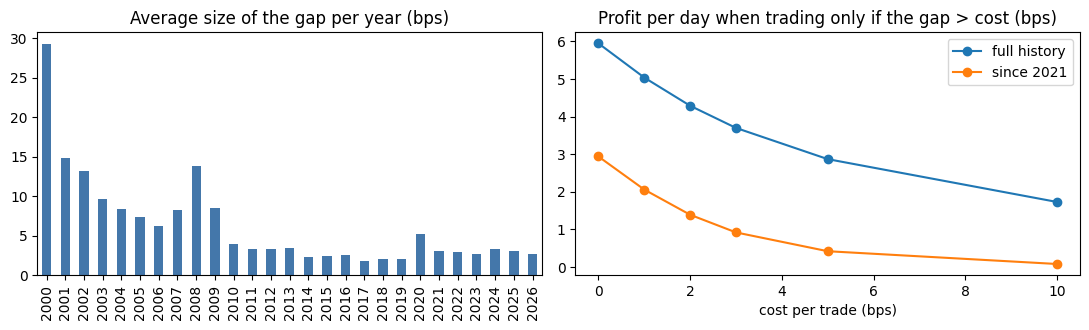

In [4]:
costs = [0, 1, 2, 3, 5, 10]


def cost_table(gaps):
    return pd.DataFrame({
        "share of days traded": [(gaps > c).mean() for c in costs],
        "profit per day, only when gap > cost (bps)": [np.maximum(gaps - c, 0).mean() for c in costs],
        "profit per day, every day (bps)": [(gaps - c).mean() for c in costs],
    }, index=pd.Index(costs, name="cost per trade (bps)")).round(2)


periods = {"full history": abs_gap, "since 2021": abs_gap["2021":]}
for name, gaps in periods.items():
    print(f"{name}: breakeven cost for trading every day = {gaps.mean():.1f} bps")
    display(cost_table(gaps))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
by_year["mean"].plot.bar(ax=ax[0], color="#4477aa")
ax[0].set(title="Average size of the gap per year (bps)", xlabel="")
for name, gaps in periods.items():
    ax[1].plot(costs, cost_table(gaps).iloc[:, 1], marker="o", label=name)
ax[1].set(title="Profit per day when trading only if the gap > cost (bps)", xlabel="cost per trade (bps)")
ax[1].legend()
plt.tight_layout()

**What the numbers say.** Trading every day, the breakeven cost is the mean gap: 5.9 bps over
the full history, but only 2.9 bps since 2021. All-in costs for a basket this large are
probably of the same order, so trading blindly every day is close to a coin flip that
depends on the cost assumption. Picking days works much better. With a 3 bps cost, since
2021 about 39% of days qualify and the net is 0.9 bps per day on the amount traded. That
is an upper bound, because it needs the gap in advance.

## Signal timing

The official NAV is only calculated after the close, so using it to decide a trade at
the close would use information nobody has at that moment. The trade decision therefore
uses our own estimate: yesterday's published basket (the exact shares of each stock),
valued at today's stock prices, plus the fund's cash, divided by the ETF shares. Only
information available on the day goes into it.

The trade itself still earns the gap to the **official NAV** of the day. The estimate
only decides whether to trade. The difference between the estimate and the official NAV
is the estimation error, which doubles as a direct measure of basket accuracy (risk 1
above).

Known simplification: the estimate uses closing prices, to match the daily model above.
In real time it would be built from live prices during the day, and the trade done as soon
as the estimate shows a gap larger than the costs. That needs intraday data.

## Signal test: own estimate from yesterday's basket

Take the last published basket (exact shares of each stock),
value it at the next trading day's stock prices, add the fund's cash, and divide by the
ETF shares outstanding. That is our own NAV estimate for the day, built with no
information from after the close of the previous day.

Because holdings history is not available, this is logged forward. The arithmetic check: the basket valued at its own prices should reproduce the official NAV
of that day. `coverage` is the share of the basket (by weight) that got a fresh price.
Stocks without a price (delisted, foreign lines, rate-limited requests) are assumed to
move like the covered part of the basket.

The estimates are kept in `iwv_estimates.csv`. Each run after a close adds the newest day
and keeps the older rows. A run during market hours adds nothing, so no intraday prices
end up in the log.

In [5]:
def close_is_final(day):
    """True once the New York close of `day` is in the past."""
    now = datetime.now(ZoneInfo("America/New_York"))
    today = pd.Timestamp(now.date())
    return day < today or (day == today and now.hour >= 17)


def download_in_chunks(tickers, size=100, passes=3, **kwargs):
    """yf.download for many tickers. Chunked and retried, because Yahoo rate-limits bulk requests."""
    parts, done = [], set()
    for _ in range(passes):
        todo = [t for t in tickers if t not in done]
        for i in range(0, len(todo), size):
            result = yf.download(todo[i:i + size], auto_adjust=False, progress=False, **kwargs)
            result = result.loc[:, result.notna().any()]
            if result.shape[1]:
                parts.append(result)
                done.update(result.columns.get_level_values(1))
            time.sleep(3)
    return pd.concat(parts, axis=1) if parts else pd.DataFrame()


def stock_closes(tickers, day):
    """Yahoo closing prices of the basket stocks for one day."""
    path = f"{DATA}/stock_closes_{day:%Y-%m-%d}.csv"
    if REFRESH or not os.path.exists(path):
        result = download_in_chunks(tickers, start=day, end=day + pd.Timedelta(days=1))
        prices = result["Close"].iloc[0].dropna() if len(result) else pd.Series(dtype=float)
        prices.rename_axis("ticker").rename("close").to_csv(path)
    return pd.read_csv(path, index_col="ticker")["close"]


def read_holdings(xml):
    """The latest published basket: date, ETF shares outstanding, stocks, and cash-like items."""
    rows = read_sheet(xml, "Holdings")
    info = {r[0]: r[1] for r in rows if len(r) == 2}
    header = next(i for i, r in enumerate(rows) if r[0] == "Ticker")
    table = pd.DataFrame(rows[header + 1:], columns=rows[header])
    for column in ("Market Value", "Quantity", "Price"):
        table[column] = pd.to_numeric(table[column].str.replace(",", ""), errors="coerce")
    is_stock = table["Asset Class"] == "Equity"
    return {
        "date": pd.to_datetime(info["Fund Holdings as of"], format="%b %d, %Y"),
        "shares_out": float(info["Shares Outstanding"].replace(",", "")),
        "stocks": table[is_stock].assign(ticker=lambda x: x["Ticker"].str.strip().str.replace(" ", "-")),
        "cash": table.loc[~is_stock, "Market Value"].sum(),  # cash, money market, margin
    }


def estimate_nav(basket):
    """Own estimate: the last published basket valued at the next trading day's closing prices."""
    later_days = closes.index[closes.index > basket["date"]]
    if later_days.empty or not close_is_final(later_days[0]):
        return None
    day, stocks = later_days[0], basket["stocks"]
    tickers = sorted(t for t in set(stocks["ticker"]) if re.fullmatch(r"[A-Z][A-Z0-9.-]*", t))
    new_price = stocks["ticker"].map(stock_closes(tickers, day))
    has_price = new_price.notna()
    # a stock without a price is assumed to move like the rest of the basket
    move = np.average(new_price[has_price] / stocks.loc[has_price, "Price"] - 1,
                      weights=stocks.loc[has_price, "Market Value"])
    new_price = new_price.fillna(stocks["Price"] * (1 + move))
    return {
        "day": day,
        "estimated_nav": ((stocks["Quantity"] * new_price).sum() + basket["cash"]) / basket["shares_out"],
        "coverage": stocks.loc[has_price, "Market Value"].sum() / stocks["Market Value"].sum(),
    }


basket = read_holdings(fund_xml[TICKER])
basket_value = (basket["stocks"]["Market Value"].sum() + basket["cash"]) / basket["shares_out"]  # per ETF share, at its own date
estimate = estimate_nav(basket)

if os.path.exists(ESTIMATES):
    estimates = pd.read_csv(ESTIMATES, index_col="date", parse_dates=True)["estimated_nav"]
else:
    estimates = pd.Series(dtype=float, name="estimated_nav", index=pd.DatetimeIndex([], name="date"))

print(f"basket as of {basket['date']:%Y-%m-%d}, arithmetic check against official NAV: "
      f"{(basket_value / iwv['nav'].get(basket['date'], np.nan) - 1) * 1e4:.2f} bps")
if estimate:
    estimates[estimate["day"]] = estimate["estimated_nav"]
    estimates.sort_index().to_csv(ESTIMATES)
    print(f"estimate for {estimate['day']:%Y-%m-%d}, price coverage {estimate['coverage']:.1%}")
else:
    print("No finished trading day after the latest basket yet, so there is nothing new to estimate.")

track_record = estimates.sort_index().to_frame().join(iwv[["nav", "gap_bps"]])
track_record["error_bps"] = (track_record["estimated_nav"] / track_record["nav"] - 1) * 1e4
track_record.round(3)

basket as of 2026-10-08, arithmetic check against official NAV: 0.04 bps
estimate for 2026-10-09, price coverage 100.0%


,estimated_nav,nav,gap_bps,error_bps
date,,,,
2026-10-09,440.726,440.771,-4.504,-1.021


**What the numbers say.** The arithmetic check passes: valued at its own prices, the basket
reproduces the official NAV to 0.04 bps. For the first logged day (9 October 2026), the
estimate built from the 8 October basket was 440.726 against an official NAV of 440.771,
an error of about 1 bp. The estimate put the ETF at a premium of about 5.5 bps at the
close and the official figure was 4.5 bps, so direction and rough size were right. This is
one observation, not a result. The track record grows by one row for every run after the
close, and the error column will show how much of the gap in Result 2 is really capturable.

## Design A: the exact stock hedge

The hedge is the same stocks in the same quantities that the swap delivers. Per ETF
share that is `quantity / ETF shares outstanding` of every stock in the basket. Because
the delivered stocks close the hedge directly, the profit is fixed by the two entry
prices and does not depend on any price after entry. Two things are checked on the
real basket: how big the hedge is, and what it does to the result on a real day.

In [6]:
weight = basket["stocks"].set_index("ticker")["Market Value"].sort_values(ascending=False)
weight = weight / weight.sum()

print(f"{len(weight)} stocks. The top 10 are {weight.head(10).sum():.1%} of the weight.")
print("stocks needed for 50% / 90% / 99% of the weight:", [int((weight.cumsum() < x).sum()) + 1 for x in (0.5, 0.9, 0.99)])
print(f"the smallest 1,000 stocks together: {weight.tail(1000).sum():.2%} of the weight")

2598 stocks. The top 10 are 34.8% of the weight.
stocks needed for 50% / 90% / 99% of the weight: [31, 463, 1589]
the smallest 1,000 stocks together: 0.98% of the weight


**What the numbers say.** The hedge is 2,598 stocks, but it is very top heavy. 31 stocks
make up half of the weight, 463 make up 90%, and it takes 1,589 to reach 99%. The smallest
1,000 stocks together are under 1% of the weight. That tail is where spreads are normally
widest and borrowing is hardest, yet it adds almost nothing to the hedge. This is the
practical side of the trade-off: the hedge is only exact if every one of those orders is
filled, and the cost of the tail is what the slippage argument is about. (Figures from the
basket of 8 October 2026.)

**A real day, hedged and unhedged.** Enter at the close of the basket date, and settle
one trading day later (T+1). In the premium case the AP shorts the ETF and buys the
basket, then creates new ETF shares to close the short. In the discount case the AP buys
the ETF and shorts the basket, then redeems. The unhedged version buys only one side and
waits. The numbers are in bps of the ETF price.

In [7]:
if estimate:
    entry_day, exit_day = basket["date"], estimate["day"]
    entry_price, exit_price = iwv.loc[entry_day, "close"], iwv.loc[exit_day, "close"]
    premium = entry_price > basket_value  # ETF above its basket: create. Otherwise redeem.
    hedged = abs(entry_price - basket_value)
    # unhedged: the second leg is traded one day later, at that day's price
    unhedged = (exit_price - basket_value) if premium else (iwv.loc[exit_day, "nav"] - entry_price)

    print(f"{entry_day:%Y-%m-%d}: {'premium, create' if premium else 'discount, redeem'}. "
          f"The ETF itself moved {(exit_price / entry_price - 1) * 1e4:+.0f} bps over the wait.")
    print((pd.Series({"hedged, exact basket": hedged, "unhedged": unhedged}) / entry_price * 1e4).round(1).to_string())

2026-10-08: premium, create. The ETF itself moved +63 bps over the wait.
hedged, exact basket     5.1
unhedged                67.8


**What the numbers say.** On 8 October the ETF closed about 5 bps above its basket, so the
trade is a creation. The exact hedge locks in that 5.1 bps. Unhedged, the same position
ended at +67.8 bps, but only because the whole market rose 63 bps during the wait. With a
63 bps fall instead, the unhedged result would have been about -58 bps for the same trade.
The gap being captured is about 5 bps, so without the hedge the market move is more than
ten times larger than the profit and decides the outcome. This is one day, an illustration
of the mechanism and not a statistical result.

**What does it cost to trade the basket?** This is the main thing in Design A that eats
the edge. Every stock is traded once to open the hedge, and each trade pays half the
bid-ask spread. That cost is one sided, so it does not average out across stocks. We
tried to estimate spreads from daily high and low prices (Corwin and Schultz, 2012). It
failed on this data, so spreads are assumed instead.

Index weight is used as a proxy for size and liquidity, and each tier gets a stated full
spread in three scenarios. Optimistic is close to zero (fills near the midpoint).
Conservative is a wide spread. Only the stock leg is counted. The ETF leg, issuer fee,
borrow and market impact come on top, so these are lower bounds.

stocks ranked 501 and below: 9% of the weight, 46% of the realistic cost


,optimistic,realistic,conservative,stocks,weight
top 100,0.1,1,3,100,0.680
101 to 500,0.5,3,8,400,0.229
501 to 1500,2.0,10,25,1000,0.079
rest,5.0,30,80,1098,0.012


,cost of the stocks (bps),share of the gap,gap left after cost (bps)
optimistic,0.20,0.07,2.74
realistic,1.26,0.43,1.68
conservative,3.41,1.16,-0.47


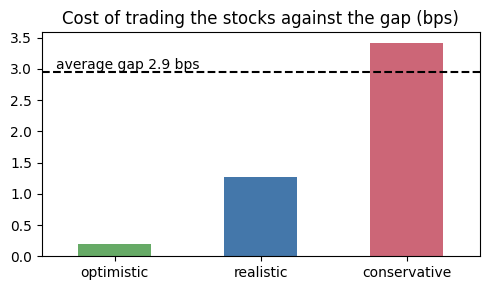

In [8]:
spreads = pd.DataFrame({  # assumed full spread in bps, by rank of index weight
    "optimistic": [0.1, 0.5, 2, 5],
    "realistic": [1, 3, 10, 30],
    "conservative": [3, 8, 25, 80],
}, index=["top 100", "101 to 500", "501 to 1500", "rest"])
tier = pd.cut(np.arange(len(weight)), [0, 100, 500, 1500, len(weight)], right=False, labels=spreads.index)
tiers = pd.DataFrame({"stocks": np.bincount(tier.codes), "weight": np.bincount(tier.codes, weights=weight.to_numpy())},
                     index=spreads.index)

average_gap = abs_gap["2021":].mean()
stock_cost = spreads.mul(tiers["weight"], axis=0).sum() / 2  # half the spread, paid once on every stock
small_stock_cost = spreads.mul(tiers["weight"], axis=0).iloc[2:].sum() / 2
print(f"stocks ranked 501 and below: {tiers['weight'].iloc[2:].sum():.0%} of the weight, "
      f"{(small_stock_cost / stock_cost)['realistic']:.0%} of the realistic cost")
display(spreads.join(tiers).round(3))
display(pd.DataFrame({"cost of the stocks (bps)": stock_cost, "share of the gap": stock_cost / average_gap,
                      "gap left after cost (bps)": average_gap - stock_cost}).round(2))

ax = stock_cost.plot.bar(color=["#66aa66", "#4477aa", "#cc6677"], rot=0, figsize=(5, 3))
ax.axhline(average_gap, color="black", ls="--")
ax.text(-0.4, average_gap, f"average gap {average_gap:.1f} bps", va="bottom")
ax.set(title="Cost of trading the stocks against the gap (bps)")
plt.tight_layout()

**What the numbers say.** The stock leg alone costs 0.2 bps in the optimistic case, 1.3 bps
in the realistic case and 3.4 bps in the conservative case, against an average gap of 2.9
bps since 2021. That is 7%, 43% and 116% of the gap. So the result of Design A is decided by
a number that daily Yahoo data cannot measure. In the conservative case the stock leg alone
is larger than the gap, before the ETF leg, fee, borrow and impact. The long tail matters
too: the stocks ranked 501 and below are 9% of the weight and add almost nothing to the
hedge, but they carry almost half of the realistic cost.

## Design B: the ETF hedge

Hedge IWV with two liquid ETFs that together cover the same stocks: IWB (Russell 1000,
large and mid cap) and IWM (Russell 2000, small cap). The hedge is sized by index ratio:
for each dollar of IWV, hold the share of IWB and IWM that the large and small cap parts
make up of IWV's basket by market value. The two shares add up to one.

The hedge ETFs are a different instrument from the stocks that the redemption delivers,
so how the position is closed matters. There are two ways, and the headline version is B2:

- **B2 (headline): create or redeem the hedge ETFs in kind.** The delivered stocks are
  handed to IWB and IWM in exchange for new ETF shares, which close the hedge. No stock
  is sold in the market. This needs AP status in all three funds. The profit is the gap
  of IWV against the gaps of the hedge ETFs (the relative gap), and the only noise is how
  well the three NAVs track each other.
- **B1 (comparison): sell the stocks, buy back the ETFs.** Market trades at the next
  close. The profit is the gap plus a basis: IWV's NAV return against the price return
  of the hedge ETFs. The redeemed stocks are still sold, so the stock spread of Design A
  is paid here too, just at exit instead of entry. B1 shows what happens when the
  position ends in stocks.

What both versions gain over Design A: no stock has to be borrowed and shorted one by
one, and the entry is three liquid ETFs.

In [9]:
navs = pd.DataFrame({ticker: nav_history(xml)["nav"] for ticker, xml in fund_xml.items()})
hedge_etfs = ["IWB", "IWM"]

# index ratio: share of IWV's basket (by market value) that sits in IWB and in IWM
iwv_value = basket["stocks"].set_index("ticker")["Market Value"]
covered = pd.Series({t: iwv_value[iwv_value.index.isin(read_holdings(fund_xml[t])["stocks"]["ticker"])].sum()
                     for t in hedge_etfs}) / iwv_value.sum()
hedge_size = covered / covered.sum()  # hedge dollars per dollar of IWV
iwm_value = read_holdings(fund_xml["IWM"])["stocks"].set_index("ticker")["Market Value"]

print(f"hedge per $1 of IWV: IWB {hedge_size['IWB']:.3f}, IWM {hedge_size['IWM']:.3f} "
      f"(IWV weight in neither: {1 - covered.sum():.1%})")
print(f"IWM weight in stocks that IWV does not hold: {iwm_value[~iwm_value.index.isin(iwv_value.index)].sum() / iwm_value.sum():.1%}")

gaps = ((navs / closes - 1) * 1e4).dropna()  # each ETF against its own NAV, bps
relative_gap = gaps[TICKER] - gaps[hedge_etfs].mul(hedge_size).sum(axis=1)
nav_return, price_return = navs.pct_change(), closes.pct_change()
b2_noise = ((nav_return[TICKER] - nav_return[hedge_etfs].mul(hedge_size).sum(axis=1)) * 1e4).dropna()  # NAV against NAV
b1_noise = ((nav_return[TICKER] - price_return[hedge_etfs].mul(hedge_size).sum(axis=1)) * 1e4).dropna()  # NAV against prices

windows = {"since 2021": lambda s: s["2021":], "last 250 days": lambda s: s.tail(250), "last 60 days": lambda s: s.tail(60)}
pd.DataFrame({
    name: {
        "IWV gap, average size (bps)": window(gaps[TICKER]).abs().mean(),
        "relative gap, average size (bps)": window(relative_gap).abs().mean(),
        "B1 noise per trade, std (bps)": window(b1_noise).std(),
        "B2 noise per trade, std (bps)": window(b2_noise).std(),
    } for name, window in windows.items()
}).round(2)

hedge per $1 of IWV: IWB 0.962, IWM 0.038 (IWV weight in neither: 0.0%)
IWM weight in stocks that IWV does not hold: 2.8%


,since 2021,last 250 days,last 60 days
"IWV gap, average size (bps)",2.94,2.67,2.54
"relative gap, average size (bps)",2.80,2.24,2.20
"B1 noise per trade, std (bps)",4.57,4.72,3.40
"B2 noise per trade, std (bps)",1.37,0.51,0.24


**What the numbers say.** The index ratio is 96% IWB and 4% IWM, and every stock in IWV sits
in one of the two funds. The three NAVs track each other very closely: the tracking noise of
B2 is 0.2 bps over the last 60 days and 0.5 bps over the last year (1.4 bps since 2021, which
includes reconstitution days). The basis of B1 is a different matter: 3.4 to 4.7 bps, as
large as the gap itself. That noise does not come from the index maths. It comes from the
closing prices of the hedge ETFs, which sit a few bps away from their own NAVs, just like
IWV does. The relative gap that B2 captures is almost as large as IWV's own gap (2.8 against
2.9 bps since 2021), because the three gaps are only partly correlated.

**Cost and edge per trade, all designs.** Same three spread scenarios. The ETFs are very
liquid, so IWV, IWB and IWM get the same assumed full spread: 0, 1 and 3 bps. Costs are
one way, in bps of the amount traded. Issuer fees are not included (A needs the IWV
fee, B2 needs three).

In [10]:
etf_half_spread = pd.Series({"optimistic": 0.0, "realistic": 1.0, "conservative": 3.0}) / 2
cost = pd.DataFrame({
    "A: exact stocks": etf_half_spread + stock_cost,              # IWV once, the stocks once
    "B2: ETF hedge, in kind": 2 * etf_half_spread,                # IWV and the hedge ETFs, at entry only
    "B1: ETF hedge, stocks sold": 3 * etf_half_spread + stock_cost,  # IWV, hedge in, hedge out, the stocks
}).T
gap = pd.Series([abs_gap["2021":].mean(), relative_gap["2021":].abs().mean(), abs_gap["2021":].mean()], index=cost.index)
noise = pd.Series([0.0, b2_noise["2021":].std(), b1_noise["2021":].std()], index=cost.index)

summary = pd.concat({"cost (bps)": cost, "profit after cost (bps)": cost.rsub(gap, axis=0)}, axis=1)
summary["gap (bps)"], summary["noise per trade, std (bps)"] = gap, noise
summary.round(2)

cost (bps)                         \
                           optimistic realistic conservative   
A: exact stocks                   0.2      1.76         4.91   
B2: ETF hedge, in kind            0.0      1.00         3.00   
B1: ETF hedge, stocks sold        0.2      2.76         7.91   

                           profit after cost (bps)                         \
                                        optimistic realistic conservative   
A: exact stocks                               2.74      1.18        -1.97   
B2: ETF hedge, in kind                        2.80      1.80        -0.20   
B1: ETF hedge, stocks sold                    2.74      0.18        -4.97   

                           gap (bps) noise per trade, std (bps)  
                                                                 
A: exact stocks                 2.94                       0.00  
B2: ETF hedge, in kind          2.80                       1.37  
B1: ETF hedge, stocks sold      2.94                       4.57

**What the numbers say.** Under the realistic spreads, B1 is no better than A: it has the
same edge, the same stock spread plus more ETF trades, and 4.6 bps of noise per trade. B2 has
the lowest cost (no stock is traded) and almost the same edge as A, so it keeps the most
after costs in every scenario. In the conservative case it still loses a little (-0.2 bps
against -2.0 bps for A), before issuer fees. The price is operational: AP status in three funds,
three creation or redemption fees, and the delivered IWV stocks do not match IWM's basket
exactly (IWV holds fewer small caps), so some names would be bought or settled in cash.
These figures use daily closes and official NAVs. In practice the trade needs estimates of
all three NAVs at the time of the trade, which is the same timing problem as for IWV.

## Conclusion

**In short:** a strategy that looks safe on paper can still lose money in practice,
and the way the position is closed decides which version survives.

| | A: exact stocks | B2 (headline): ETF hedge, in kind | B1 (comparison): ETF hedge, stocks sold |
|---|---|---|---|
| What is traded | the ETF and about 2,600 stocks | the ETF and two ETFs only | the ETF, two ETFs, then the stocks |
| How the hedge is closed | delivery of the same stocks | hedge ETFs created or redeemed with the stocks | stocks sold, ETFs bought back |
| Main risk | execution: slippage, missed fills, borrow | NAV tracking, and the signal needs three estimates | basis noise from the hedge ETFs' prices |
| Needs | cheap and accurate execution in every name | AP status in three funds, three fees | A's stock trades plus ETF trades |

**Design A has the most room to fail on cost.** Slippage is one sided: it costs money on
average and does not net out across stocks. The noise around that average shrinks as
stocks are added, but the average does not, so the cost of the trade is roughly the
weighted spread of the basket, whatever the number of names. The number of names matters
in other ways. The chance that at least one order misses its target price, or that one
short cannot be borrowed, approaches certainty with thousands of names, and then the
hedge is no longer exact. If the cost of the basket is close to the size of the gap, the
edge is gone and the strategy sits at or near breakeven.

**Design B2 is where the ETF hedge pays off,** because no stock is traded at all. It
relies on precise ETF values: the edge is a relative gap between three ETFs, which is
only as good as the estimates of three NAVs at the time of the trade.

**Design B1 does not avoid the stock cost.** The redeemed stocks still have to be sold,
so the stock spread is paid anyway, and the hedge ETFs add their own trades and a basis
noise of the same size as the gap. Its benefit is operational (nothing to borrow, the
stocks can be sold over the day), not economic.

**The data limit.** Daily Yahoo prices are probably not precise enough to measure costs
or to build those estimates, as the failed attempt to estimate spreads from daily prices
suggests. A follow-up study with intraday quotes would be needed to settle it.

**What would change this conclusion:** a measured cost of the stock leg well below the gap,
or a B2 relative gap that does not hold up once costs and fees for three funds are
counted.

**Where the numbers stand.** The average gap is 2.9 bps since 2021. Design A pays 0.2, 1.8 or
4.9 bps depending on the spread scenario, so it is at or below breakeven in the conservative
case. Design B1 is worse than A. Design B2 pays 0, 1 or 3 bps for a similar edge and holds up
best, but needs AP status in three funds and measured NAV estimates that this data cannot
provide. It points to B2 as the version worth
the follow-up study.

## Scope and limitations

- Analytical only. No real money, no live execution, and no actual AP status. The
  analysis assumes trades can be done at observed historical prices, and every assumption
  about fills and costs is stated where it is used.
- Daily data is a snapshot at the close. It cannot show gaps that open and close during
  the day.
- The closing gap compares the ETF's last trade with NAV. Some of it is measurement noise,
  not an opportunity.
- Trading only on days with a gap above the cost (Result 2) assumes perfect foresight, so
  it is an upper bound. The own estimate is the honest test of how much of it can be
  captured, and it has one day of history so far.
- The own estimate ignores the dividend the fund accrues on ex-dividend days, which pushes
  the estimate below NAV on those days. It also misses same-day rebalances and corporate
  actions.
- A few delisted or foreign lines have no Yahoo price. They are assumed to move like the rest
  of the basket, and the coverage is reported.
- Spreads are scenarios. Issuer fees, borrow fees and market impact are not counted.

## Literature

- Engle, R., & Sarkar, D. (2006). *Premiums-Discounts and Exchange Traded Funds.*
  Journal of Derivatives. Study of how ETF premiums and discounts behave.
- Petajisto, A. (2017). *Inefficiencies in the Pricing of Exchange-Traded Funds.*
  Financial Analysts Journal. Documents persistent premiums and discounts across ETF
  types.
- Madhavan, A. (2016). *Exchange-Traded Funds and the New Dynamics of Investing.*
  Reference for how creation and redemption work.
- Corwin, S., & Schultz, P. (2012). *A Simple Way to Estimate Bid-Ask Spreads from Daily
  High and Low Prices.* Journal of Finance. The spread estimate tried in Design A.

## Next steps

- Run the notebook after each close with `REFRESH = True`. The estimate error log is the
  main new result.
- Replace the assumed spreads with measured quotes (a follow-up with intraday quote data).
- Track the gap during the day, not only at the close.
- Add the issuer fees from the prospectus, borrow and financing.

Strategy metrics such as the Sharpe ratio or drawdown are left out on purpose. The hedged
profit is fixed at entry, so its day-to-day volatility is close to zero by construction.
A Sharpe ratio would look excellent and say nothing. The real risks here are costs and
execution, which these metrics do not capture.